# Netflix Content Evolution: Exploratory Data Analysis

**Assignment:** Netflix Project Assignment I — Jupyter Notebook Submission  
**Selected challenge:** Challenge 3 — The Evolution of Netflix Content  
**Business question:** *How has Netflix's content library changed over time?*

**Team members:** Ankit Kar and Dhruv Joshi  
**Course:** [IT 545 Object-Oriented Programming in Python]  
**Date:** [22-11-2026]

---

## 1. Project overview

This notebook examines the historical evolution of titles represented in a Netflix catalog dataset. It explores two different time dimensions:

- **Release year:** when a movie or television programme was originally released.
- **Date added:** when the title was recorded as being added to Netflix in the dataset.

The analysis compares Movies and TV Shows, examines annual additions, and describes the age profile of catalogued content. The objective is to generate descriptive business insights from catalog metadata.

### Scope and limitations

The dataset contains title-level metadata. It does **not** contain viewing hours, audience ratings, completion rates, subscription data, licensing costs, or other measures of performance. Therefore, this project cannot determine whether a title was popular, profitable, or successful with viewers. It also represents a historical third-party dataset snapshot, not Netflix's live catalog in 2026.

## Team responsibilities

- **Ankit Kar:** project coordination, exploratory analysis, visualisations, interpretation, and final report integration.
- **Dhruv Joshi:** dataset inspection, data cleaning, notebook execution checks, and version-control support.
- **Joint work:** scope confirmation, review of business insights, quality assurance, and final submission approval.


## 2. Dataset and source

The project uses the **Netflix Movies and TV Shows** dataset credited to Shivam Bansal on Kaggle and mirrored for the TidyTuesday project dated 20 April 2021. The TidyTuesday README states that the data was collected from Flixable, a third-party Netflix search engine. The dataset includes fields such as `type`, `title`, `date_added`, `release_year`, `country`, `rating`, and `listed_in`.

- Dataset documentation: [TidyTuesday README (20 April 2021)](https://github.com/rfordatascience/tidytuesday/blob/main/data/2021/2021-04-20/readme.md)
- CSV source: [netflix_titles.csv](https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-04-20/netflix_titles.csv)
- Original Kaggle dataset: [Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows)

**Reproducibility note:** The code first looks for `data/netflix_titles.csv` beside this notebook. If the file is not present, it attempts to download the cited CSV source. For an offline run, download the CSV manually and save it in the `data` folder.

## 3. Import libraries

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-04-20/netflix_titles.csv"
DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "netflix_titles.csv"

## 4. Load the dataset

In [2]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    print("Local CSV not found. Attempting to download the documented dataset source...")
    try:
        urlretrieve(DATA_URL, DATA_PATH)
        print(f"Dataset downloaded to: {DATA_PATH.resolve()}")
    except Exception as exc:
        raise FileNotFoundError(
            "Could not find data/netflix_titles.csv and automatic download failed. "
            "Download the CSV from the source link in Section 2 and save it as "
            "data/netflix_titles.csv, then re-run the notebook."
        ) from exc

raw_df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded successfully: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns.")
display(raw_df.head())

Dataset loaded successfully: 7,787 rows and 12 columns.


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


## 5. Inspect the dataset

In [3]:
print("Dataset dimensions:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())
print("\nData types and non-null counts:")
raw_df.info()

Dataset dimensions: (7787, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB


In [4]:
print("Descriptive summary for numeric columns:")
display(raw_df.describe(include=[np.number]).T)

print("Missing values by column:")
missing_summary = raw_df.isna().sum().sort_values(ascending=False).to_frame("missing_values")
missing_summary["missing_percent"] = (missing_summary["missing_values"] / len(raw_df) * 100).round(2)
display(missing_summary)

Descriptive summary for numeric columns:


,count,mean,std,min,25%,50%,75%,max
release_year,7787.0,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0


Missing values by column:


,missing_values,missing_percent
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00
duration,0,0.00


## 6. Data cleaning and preparation

The cleaning process is deliberately conservative. Blank text is standardised as missing data, exact duplicate rows are removed, and date/year fields are converted to appropriate types. Missing directors, cast members, countries, ratings, or dates are not filled with invented values. In particular, records without a valid `date_added` are excluded only from analyses that require an addition year.

In [5]:
netflix_df = raw_df.copy()

# Standardise whitespace in text fields and convert empty strings to missing values.
text_columns = netflix_df.select_dtypes(include="object").columns
for column in text_columns:
    netflix_df[column] = netflix_df[column].str.strip()
netflix_df = netflix_df.replace(r"^\s*$", np.nan, regex=True)

# Remove only exact duplicate rows; preserve titles with distinct identifiers/metadata.
exact_duplicates = int(netflix_df.duplicated().sum())
netflix_df = netflix_df.drop_duplicates().copy()

# Convert analysis fields into consistent numeric/date formats.
netflix_df["release_year"] = pd.to_numeric(netflix_df["release_year"], errors="coerce")
netflix_df["date_added_parsed"] = pd.to_datetime(
    netflix_df["date_added"], format="%B %d, %Y", errors="coerce"
)
netflix_df["year_added"] = netflix_df["date_added_parsed"].dt.year
netflix_df["release_to_addition_years"] = netflix_df["year_added"] - netflix_df["release_year"]

cleaning_summary = pd.DataFrame({
    "measure": [
        "Rows before cleaning",
        "Exact duplicate rows removed",
        "Rows after exact duplicate removal",
        "Rows with a valid date_added",
        "Rows with missing/unparseable date_added",
        "Rows with missing release_year",
        "Rows with negative release-to-addition gap"
    ],
    "value": [
        len(raw_df),
        exact_duplicates,
        len(netflix_df),
        int(netflix_df["date_added_parsed"].notna().sum()),
        int(netflix_df["date_added_parsed"].isna().sum()),
        int(netflix_df["release_year"].isna().sum()),
        int((netflix_df["release_to_addition_years"] < 0).sum())
    ]
})
display(cleaning_summary)

,measure,value
0,Rows before cleaning,7787
1,Exact duplicate rows removed,0
2,Rows after exact duplicate removal,7787
3,Rows with a valid date_added,7777
4,Rows with missing/unparseable date_added,10
5,Rows with missing release_year,0
6,Rows with negative release-to-addition gap,12


### 6.1 Check the cleaned data

The next checks confirm that the key fields are available and that the transformed date and year columns have the expected types.

In [6]:
required_columns = {"show_id", "type", "title", "release_year", "date_added", "date_added_parsed", "year_added"}
missing_required = required_columns.difference(netflix_df.columns)
if missing_required:
    raise ValueError(f"Required columns are missing from the dataset: {sorted(missing_required)}")

print("Cleaned dataset shape:", netflix_df.shape)
print("Duplicate rows remaining:", int(netflix_df.duplicated().sum()))
print("Duplicate show_id values:", int(netflix_df["show_id"].duplicated().sum()))
print("\nCleaned data types:")
print(netflix_df[["type", "release_year", "date_added_parsed", "year_added"]].dtypes)
display(netflix_df.head())

Cleaned dataset shape: (7787, 15)
Duplicate rows remaining: 0
Duplicate show_id values: 0

Cleaned data types:
type                         object
release_year                  int64
date_added_parsed    datetime64[ns]
year_added                  float64
dtype: object


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,date_added_parsed,year_added,release_to_addition_years
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...,2020-08-14,2020.0,0.0
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...,2016-12-23,2016.0,0.0
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow...",2018-12-20,2018.0,7.0
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi...",2017-11-16,2017.0,8.0
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...,2020-01-01,2020.0,12.0


## 7. Exploratory data analysis (EDA)

### 7.1 Overall catalog composition

This section compares the number and share of Movies and TV Shows represented in the dataset. The results describe catalog composition only; they are not measures of viewing or popularity.

In [7]:
type_counts = netflix_df["type"].value_counts(dropna=False).rename_axis("content_type").to_frame("title_count")
type_counts["share_percent"] = (type_counts["title_count"] / type_counts["title_count"].sum() * 100).round(2)
display(type_counts)

,title_count,share_percent
content_type,,
Movie,5377,69.05
TV Show,2410,30.95


### 7.2 Titles added to Netflix by year

`date_added` is used to estimate the number of titles added in each calendar year. Rows with missing or unparseable dates cannot be assigned to an addition year and are excluded from this specific analysis.

type,Movie,TV Show
year_added,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,5
2014.0,19,6
2015.0,58,30
2016.0,258,185


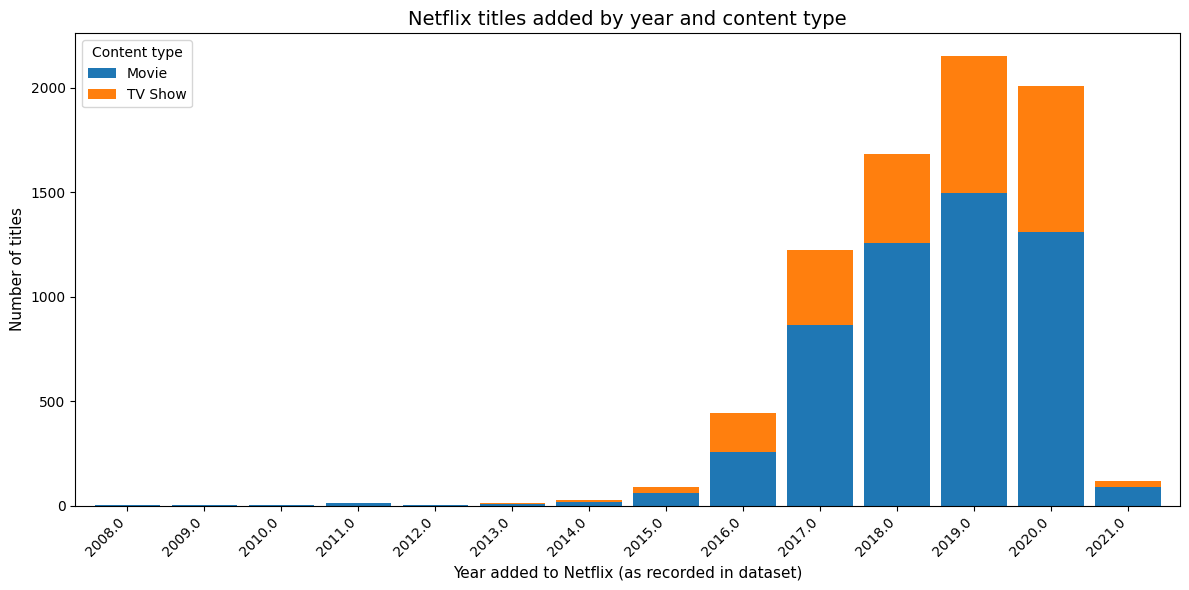

In [8]:
addition_df = netflix_df.dropna(subset=["year_added", "type"]).copy()
added_by_year_type = (
    addition_df.groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

display(added_by_year_type.tail(15))

ax = added_by_year_type.plot(kind="bar", stacked=True, figsize=(12, 6), width=0.85)
ax.set_title("Netflix titles added by year and content type")
ax.set_xlabel("Year added to Netflix (as recorded in dataset)")
ax.set_ylabel("Number of titles")
ax.legend(title="Content type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 7.3 Original release-year distribution

This analysis uses `release_year`, not `date_added`. It helps show whether the catalog snapshot contains mostly recent releases or a substantial back-catalogue of older titles.

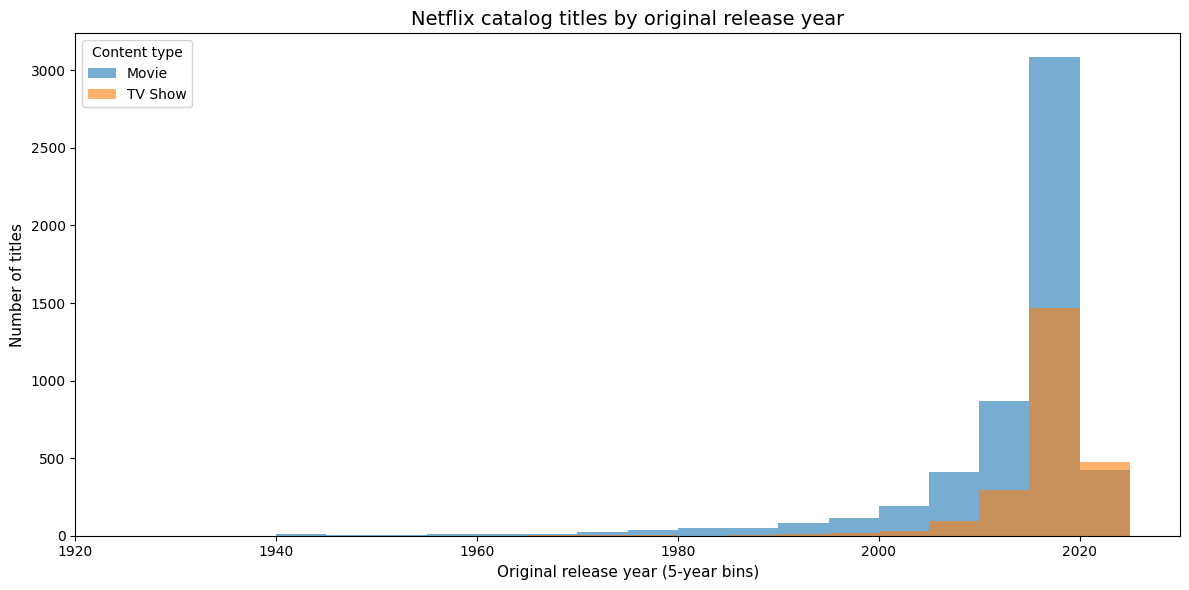

In [9]:
release_df = netflix_df.dropna(subset=["release_year", "type"]).copy()
release_min = int(release_df["release_year"].min())
release_max = int(release_df["release_year"].max())
bin_start = (release_min // 5) * 5
release_bins = np.arange(bin_start, release_max + 6, 5)

fig, ax = plt.subplots(figsize=(12, 6))
for content_type in sorted(release_df["type"].dropna().unique()):
    values = release_df.loc[release_df["type"] == content_type, "release_year"]
    ax.hist(values, bins=release_bins, alpha=0.60, label=content_type)
ax.set_title("Netflix catalog titles by original release year")
ax.set_xlabel("Original release year (5-year bins)")
ax.set_ylabel("Number of titles")
ax.legend(title="Content type")
plt.tight_layout()
plt.show()

### 7.4 Catalog composition by release decade

Grouping release years into decades makes longer-term changes easier to compare. This chart counts the titles in the dataset by their original release decade and content type.

type,Movie,TV Show
release_decade,,
1920,0,1
1940,13,1
1950,11,0
1960,22,3
1970,63,4
1980,99,7
1990,194,31
2000,601,127
2010,3951,1760


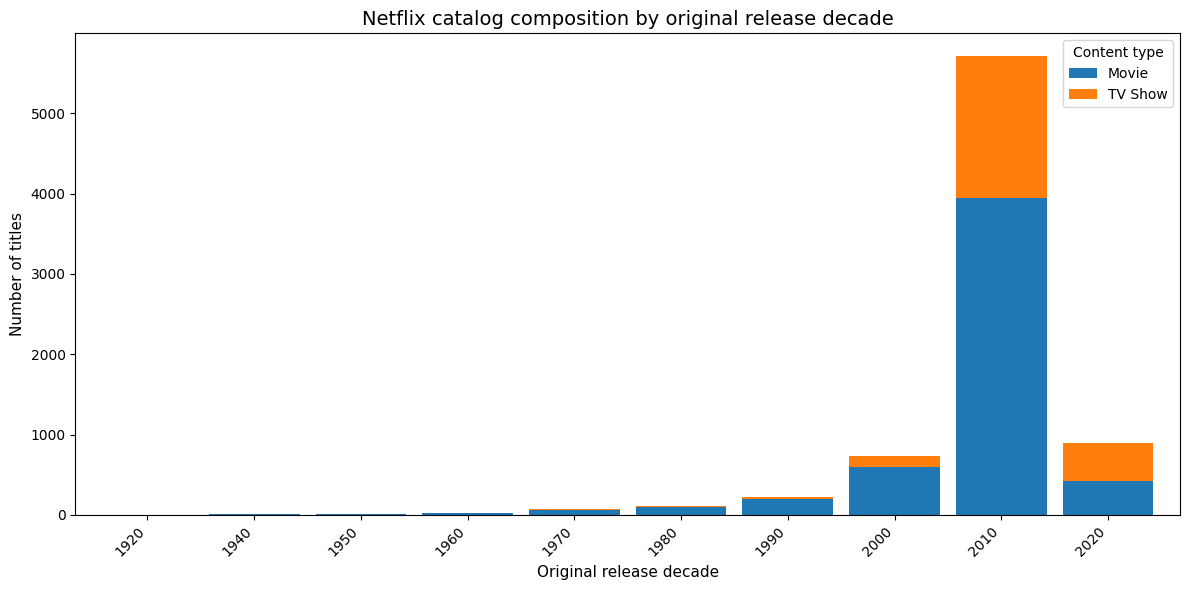

In [10]:
release_df["release_decade"] = (release_df["release_year"] // 10 * 10).astype(int)
decade_by_type = (
    release_df.groupby(["release_decade", "type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
display(decade_by_type)

ax = decade_by_type.plot(kind="bar", stacked=True, figsize=(12, 6), width=0.85)
ax.set_title("Netflix catalog composition by original release decade")
ax.set_xlabel("Original release decade")
ax.set_ylabel("Number of titles")
ax.legend(title="Content type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 7.5 Time between original release and addition to Netflix

For records with both dates/years available, the difference between `year_added` and `release_year` is used as a simple year-level approximation of catalog lag. This is not an exact day-level licensing measure. Negative gaps are treated as data anomalies and excluded from the lag summary rather than silently corrected.

,title_count,median_years,mean_years
type,,,
Movie,5375,1.0,5.56
TV Show,2390,0.0,2.33


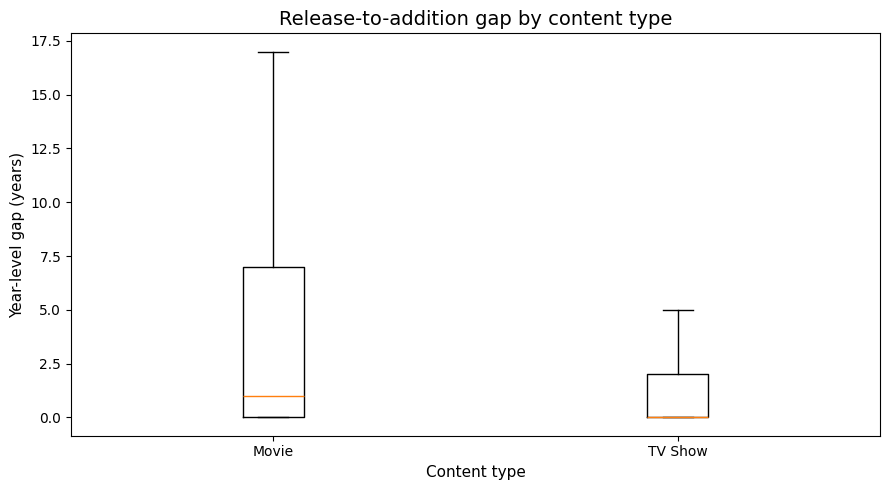

In [11]:
lag_df = netflix_df.dropna(subset=["release_to_addition_years", "type"]).copy()
lag_df = lag_df.loc[lag_df["release_to_addition_years"] >= 0]

lag_summary = (
    lag_df.groupby("type")["release_to_addition_years"]
    .agg(title_count="count", median_years="median", mean_years="mean")
    .round(2)
)
display(lag_summary)

if not lag_df.empty:
    plot_data = [
        lag_df.loc[lag_df["type"] == content_type, "release_to_addition_years"].values
        for content_type in sorted(lag_df["type"].dropna().unique())
    ]
    labels = sorted(lag_df["type"].dropna().unique())
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.boxplot(plot_data, tick_labels=labels, showfliers=False)
    ax.set_title("Release-to-addition gap by content type")
    ax.set_xlabel("Content type")
    ax.set_ylabel("Year-level gap (years)")
    plt.tight_layout()
    plt.show()
else:
    print("No valid non-negative release-to-addition gaps are available to plot.")

## 8. Business insights

The following statements are calculated directly from the loaded dataset when the notebook is run. They are descriptive insights about the dataset's catalog snapshot, not causal conclusions or measures of audience demand.

In [12]:
# Insight 1: composition of the catalog.
known_type_counts = netflix_df["type"].dropna().value_counts()
if not known_type_counts.empty:
    dominant_type = known_type_counts.idxmax()
    dominant_share = known_type_counts.max() / known_type_counts.sum() * 100
    print(
        f"Insight 1 — Catalog composition: {dominant_type} is the largest content category, "
        f"representing {dominant_share:.1f}% of records with a known content type."
    )
else:
    print("Insight 1 — Catalog composition: content type is unavailable for all records.")

# Insight 2: peak year of catalog additions.
annual_additions = addition_df.groupby("year_added").size().sort_index()
if not annual_additions.empty:
    peak_year = int(annual_additions.idxmax())
    peak_total = int(annual_additions.max())
    print(
        f"Insight 2 — Addition activity: the largest number of titles in this snapshot "
        f"was recorded in {peak_year} ({peak_total:,} titles)."
    )
else:
    print("Insight 2 — Addition activity: no valid addition dates are available.")

# Insight 3: age of the catalog when titles were added.
valid_lag = netflix_df.loc[netflix_df["release_to_addition_years"] >= 0, "release_to_addition_years"].dropna()
if not valid_lag.empty:
    median_lag = float(valid_lag.median())
    print(
        f"Insight 3 — Catalog age: the median year-level gap between original release "
        f"and addition to Netflix is {median_lag:.1f} years among records with valid dates."
    )
else:
    print("Insight 3 — Catalog age: insufficient valid release/addition year pairs.")

# Additional insight: share of catalog titles originally released in 2010 or later.
if not release_df.empty:
    recent_share = (release_df["release_year"] >= 2010).mean() * 100
    print(
        f"Additional observation — Recent-release mix: {recent_share:.1f}% of titles "
        f"with a valid release year were originally released in 2010 or later."
    )

Insight 1 — Catalog composition: Movie is the largest content category, representing 69.1% of records with a known content type.
Insight 2 — Addition activity: the largest number of titles in this snapshot was recorded in 2019 (2,153 titles).
Insight 3 — Catalog age: the median year-level gap between original release and addition to Netflix is 1.0 years among records with valid dates.
Additional observation — Recent-release mix: 84.9% of titles with a valid release year were originally released in 2010 or later.


## 9. Business recommendations

Recommendations should be interpreted in line with the evidence and limitations of this dataset:

1. **Monitor catalog freshness by format.** Track original release-year distributions separately for Movies and TV Shows to understand how the age profile of the catalog changes.
2. **Separate acquisition activity from release activity.** Report `year_added` and `release_year` as different KPIs; they measure different events and should not be used interchangeably.
3. **Use a broader evidence base for content investment decisions.** Combine catalog metadata with viewing hours, completion rates, licensing costs, retention, and regional demand before deciding which genres or titles deserve more investment.

## 10. Conclusion

This project describes how the Netflix catalog represented in the selected historical dataset varies by content type, original release year, and recorded addition year. The charts and calculated insights distinguish the age of content from the timing of its addition to the platform. Because the dataset contains catalog metadata rather than viewing behaviour, the findings support descriptive catalog planning but cannot establish title popularity or business performance.

**Final validation before submission:** Run every cell from top to bottom, confirm all four charts display, check the generated insights, save the executed notebook, and capture a screenshot showing the final successful output.

## 11. References

- TidyTuesday. (2021, April 20). *Netflix Shows — data README*. https://github.com/rfordatascience/tidytuesday/blob/main/data/2021/2021-04-20/readme.md
- Bansal, S. (n.d.). *Netflix Movies and TV Shows* [Dataset]. Kaggle. https://www.kaggle.com/datasets/shivamb/netflix-shows
- TidyTuesday. (2021, April 20). *netflix_titles.csv* [Data file]. https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-04-20/netflix_titles.csv